In [2]:
import zipfile
import os

# Đường dẫn tới file zip
zip_path = '/content/Fake vs Real Photo.zip'
extract_path = '/content/dataset'

# Giải nén file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# Định nghĩa đường dẫn đến tập train và test
train_dir = os.path.join(extract_path, 'train')
test_dir = os.path.join(extract_path, 'test')

print("Cấu trúc thư mục train:", os.listdir(train_dir))
print("Cấu trúc thư mục test:", os.listdir(test_dir))

Cấu trúc thư mục train: ['FAKE', 'REAL']
Cấu trúc thư mục test: ['FAKE', 'REAL']


Thiết lập Khởi tạo và Tăng cường Dữ liệu (Data Augmentation)

In [3]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Cấu hình kích thước ảnh và batch size
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Tăng cường dữ liệu cho tập TRAIN (giúp tránh học vẹt)
train_datagen = ImageDataGenerator(
    rescale=1./255,          # Chuẩn hóa giá trị pixel từ [0-255] về [0-1]
    rotation_range=20,       # Xoay ảnh ngẫu nhiên trong khoảng 20 độ
    width_shift_range=0.2,   # Dịch ảnh theo chiều ngang
    height_shift_range=0.2,  # Dịch ảnh theo chiều dọc
    shear_range=0.2,         # Biến dạng ảnh
    zoom_range=0.2,          # Phóng to/thu nhỏ ngẫu nhiên
    horizontal_flip=True,    # Lật ảnh ngẫu nhiên theo chiều ngang
    validation_split=0.2     # Tách 20% dữ liệu train làm tập Validation (Xác thực)
)

# Tập TEST chỉ chuẩn hóa pixel, KHÔNG tăng cường để đảm bảo tính khách quan
test_datagen = ImageDataGenerator(rescale=1./255)


Tạo các Data Loader để nạp ảnh vào Mô hình

In [4]:
import os

# Định nghĩa đường dẫn dựa trên cấu trúc thư mục
train_dir = '/content/dataset/train'
test_dir = '/content/dataset/test'


# 1. Loader cho tập huấn luyện (Training Set)
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',     # Bài toán phân loại 2 lớp (Fake vs Real)
    subset='training'        # Lấy phần huấn luyện (80%)
)

# 2. Loader cho tập xác thực (Validation Set)
val_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation'      # Lấy phần xác thực (20%)
)

# 3. Loader cho tập kiểm tra (Testing Set)
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False            # Không xáo trộn tập test để dễ đánh giá sau này
)

# Kiểm tra ánh xạ nhãn lớp (Class Indices)
print("Ánh xạ nhãn:", train_generator.class_indices)

Found 80000 images belonging to 2 classes.
Found 20000 images belonging to 2 classes.
Found 20000 images belonging to 2 classes.
Ánh xạ nhãn: {'FAKE': 0, 'REAL': 1}


Huấn luyện mô hình

In [5]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping


# 1. XÂY DỰNG CẤU TRÚC MÔ HÌNH (MOBILE NET V2)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False  # Đóng băng trọng số mô hình gốc

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])


# 2. BIÊN DỊCH MÔ HÌNH (COMPILE)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)


# 3. TIẾN HÀNH HUẤN LUYỆN (FIT)
# Tự động dừng nếu mô hình không cải thiện sau 3 vòng lặp để tiết kiệm thời gian
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

print("--- Bắt đầu quá trình huấn luyện mô hình ---")
history = model.fit(
    train_generator,
    epochs=3,
    validation_data=val_generator,
    callbacks=[early_stopping]
)
print("--- Huấn luyện hoàn tất! ---")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
--- Bắt đầu quá trình huấn luyện mô hình ---
Epoch 1/3
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 603s 231ms/step - accuracy: 0.8173 - loss: 0.4043 - val_accuracy: 0.8561 - val_loss: 0.3318
Epoch 2/3
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 521s 208ms/step - accuracy: 0.8448 - loss: 0.3548 - val_accuracy: 0.8648 - val_loss: 0.3085
Epoch 3/3
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 441s 176ms/step - accuracy: 0.8513 - loss: 0.3427 - val_accuracy: 0.8719 - val_loss: 0.2996
--- Huấn luyện hoàn tất! ---


Đánh giá mô hình

In [6]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

print("--- Đang tiến hành đánh giá mô hình trên tập Test (20.000 ảnh) ---")

# 1. Đánh giá tổng quan (Loss và Accuracy)
test_loss, test_acc = model.evaluate(test_generator)
print(f"\n📊 KẾT QUẢ TỔNG QUAN:")
print(f"   - Độ chính xác (Accuracy) trên tập Test: {test_acc * 100:.2f}%")
print(f"   - Giá trị mất mát (Loss) trên tập Test:  {test_loss:.4f}")

# 2. Dự đoán nhãn cho toàn bộ tập Test để tính toán các độ đo chi tiết
print("\n🔄 Đang chạy dự đoán trên 20.000 ảnh tập Test (Vui lòng đợi giây lát)...")
test_generator.reset() # Đưa bộ đọc ảnh về trạng thái đầu tiên
predictions = model.predict(test_generator)

# Chuyển đổi xác suất (0 đến 1) từ hàm Sigmoid thành nhãn 0 (FAKE) hoặc 1 (REAL)
# Nếu xác suất lớn hơn 0.5 thì đoán là REAL, ngược lại là FAKE
predicted_classes = (predictions > 0.5).astype(int).flatten()
true_classes = test_generator.classes

# 3. In bảng báo cáo hiệu suất chi tiết (Classification Report)
print("\n📋 BÁO CÁO HIỆU SUẤT CHI TIẾT (CLASSIFICATION REPORT):")
print(classification_report(true_classes, predicted_classes, target_names=['FAKE', 'REAL'], digits=4))


--- Đang tiến hành đánh giá mô hình trên tập Test (20.000 ảnh) ---
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.8126 - loss: 0.4116

📊 KẾT QUẢ TỔNG QUAN:
   - Độ chính xác (Accuracy) trên tập Test: 81.26%
   - Giá trị mất mát (Loss) trên tập Test:  0.4116

🔄 Đang chạy dự đoán trên 20.000 ảnh tập Test (Vui lòng đợi giây lát)...
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step

📋 BÁO CÁO HIỆU SUẤT CHI TIẾT (CLASSIFICATION REPORT):
              precision    recall  f1-score   support

        FAKE     0.9255    0.6798    0.7839     10000
        REAL     0.7470    0.9453    0.8345     10000

    accuracy                         0.8125     20000
   macro avg     0.8363    0.8125    0.8092     20000
weighted avg     0.8363    0.8125    0.8092     20000



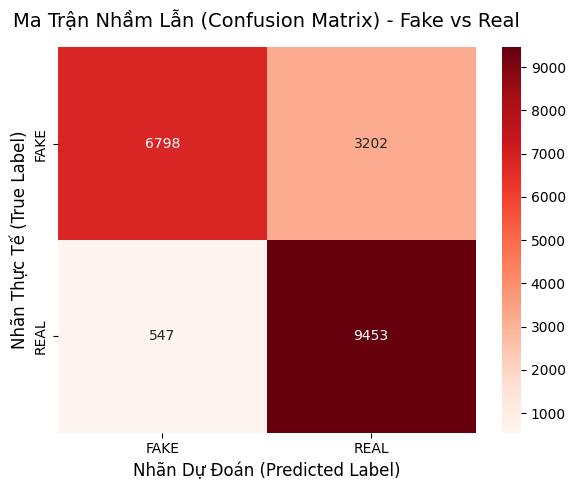

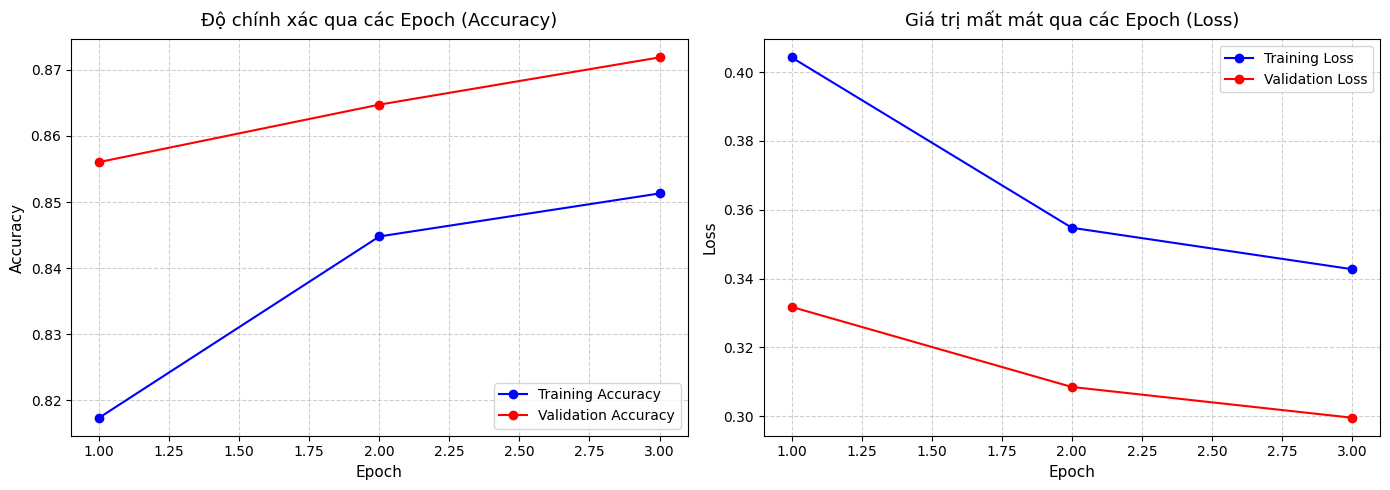

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Tính toán ma trận nhầm lẫn từ nhãn thực tế và nhãn dự đoán
cm = confusion_matrix(true_classes, predicted_classes)

# 2. Cấu hình kích thước và giao diện biểu đồ
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,          # Hiển thị số lượng ảnh trên từng ô
    fmt='d',             # Định dạng số nguyên (không hiển thị số thập phân)
    cmap='Reds',        # Tông màu đỏ trực quan
    xticklabels=['FAKE', 'REAL'], # Nhãn trục hoành (Dự đoán)
    yticklabels=['FAKE', 'REAL']  # Nhãn trục tung (Thực tế)
)

# 3. Thêm tiêu đề và nhãn cho các trục
plt.title('Ma Trận Nhầm Lẫn (Confusion Matrix) - Fake vs Real', fontsize=14, pad=15)
plt.ylabel('Nhãn Thực Tế (True Label)', fontsize=12)
plt.xlabel('Nhãn Dự Đoán (Predicted Label)', fontsize=12)

# 4. Hiển thị biểu đồ lên màn hình Colab
plt.tight_layout()
plt.show()


# Lấy dữ liệu lịch sử huấn luyện từ biến history
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)


#----------------------------------------------------
# Thiết lập kích thước khung hình cho cả 2 biểu đồ
plt.figure(figsize=(14, 5))


# 1. BIỂU ĐỒ ĐỘ CHÍNH XÁC (ACCURACY GRAPH)

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'b-o', label='Training Accuracy')
plt.plot(epochs_range, val_acc, 'r-o', label='Validation Accuracy')
plt.title('Độ chính xác qua các Epoch (Accuracy)', fontsize=13, pad=10)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Accuracy', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')


# 2. BIỂU ĐỒ GIÁ TRỊ MẤT MÁT (LOSS GRAPH)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'b-o', label='Training Loss')
plt.plot(epochs_range, val_loss, 'r-o', label='Validation Loss')
plt.title('Giá trị mất mát qua các Epoch (Loss)', fontsize=13, pad=10)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')

# Hiển thị cặp biểu đồ
plt.tight_layout()
plt.show()



In [10]:
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# 1. MỞ KHÓA SÂU HƠN CÁC TẦNG MẠNG NỀN
base_model.trainable = True

# Đóng băng 80 tầng đầu, mở khóa từ tầng 80 trở đi để tinh chỉnh nâng cao
fine_tune_at = 80
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# 2. BIÊN DỊCH LẠI VỚI TỐC ĐỘ HỌC NHỎ (LOW LEARNING RATE)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 3. THIẾT LẬP CÁC CALLBACKS TỐI ƯU HÓA THÔNG MINH
# ĐÃ ĐỒNG BỘ TÊN BIẾN LÀ lr_reducer
lr_reducer = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=1,
    min_lr=1e-7,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

# 4. TIÊN HÀNH HUẤN LUYỆN TINH CHỈNH NÂNG CAO (FINE-TUNE FIT)
print("\n--- Bắt đầu quá trình Tối ưu hóa mô hình nâng cao ---")
fine_tune_epochs = 3

# Cấu hình phạt nặng gấp 1.5 lần nếu bỏ sót ảnh FAKE (nhãn 0)
custom_class_weight = {0: 1.5, 1: 1.0}

history_fine = model.fit(
    train_generator,
    epochs=fine_tune_epochs,
    validation_data=val_generator,
    callbacks=[early_stopping, lr_reducer], # Đã khớp tên biến hoàn toàn
    class_weight=custom_class_weight
)

print("--- Tối ưu hóa hoàn tất! ---")





--- Bắt đầu quá trình Tối ưu hóa mô hình nâng cao ---
Epoch 1/3
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 502s 189ms/step - accuracy: 0.8947 - loss: 0.3197 - val_accuracy: 0.9215 - val_loss: 0.2049 - learning_rate: 1.0000e-04
Epoch 2/3
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 465s 186ms/step - accuracy: 0.9303 - loss: 0.2167 - val_accuracy: 0.9331 - val_loss: 0.1856 - learning_rate: 1.0000e-04
Epoch 3/3
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 521s 208ms/step - accuracy: 0.9413 - loss: 0.1829 - val_accuracy: 0.9455 - val_loss: 0.1519 - learning_rate: 1.0000e-04
--- Tối ưu hóa hoàn tất! ---


In [25]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

print("--- Đang tiến hành đánh giá mô hình trên tập Test (20.000 ảnh) ---")

# 1. Đánh giá tổng quan (Loss và Accuracy)
test_loss, test_acc = model.evaluate(test_generator)
print(f"\n📊 KẾT QUẢ TỔNG QUAN:")
print(f"   - Độ chính xác (Accuracy) trên tập Test: {test_acc * 100:.2f}%")
print(f"   - Giá trị mất mát (Loss) trên tập Test:  {test_loss:.4f}")

# 2. Dự đoán nhãn cho toàn bộ tập Test để tính toán các độ đo chi tiết
print("\n🔄 Đang chạy dự đoán trên 20.000 ảnh tập Test (Vui lòng đợi giây lát)...")
test_generator.reset() # Đưa bộ đọc ảnh về trạng thái đầu tiên
predictions = model.predict(test_generator)

# Chuyển đổi xác suất (0 đến 1) từ hàm Sigmoid thành nhãn 0 (FAKE) hoặc 1 (REAL)
# Nếu xác suất lớn hơn 0.5 thì đoán là REAL, ngược lại là FAKE
predicted_classes = (predictions > 0.50).astype(int).flatten()
true_classes = test_generator.classes

# 3. In bảng báo cáo hiệu suất chi tiết (Classification Report)
print("\n📋 BÁO CÁO HIỆU SUẤT CHI TIẾT (CLASSIFICATION REPORT):")
print(classification_report(true_classes, predicted_classes, target_names=['FAKE', 'REAL'], digits=4))

--- Đang tiến hành đánh giá mô hình trên tập Test (20.000 ảnh) ---
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.9433 - loss: 0.1650

📊 KẾT QUẢ TỔNG QUAN:
   - Độ chính xác (Accuracy) trên tập Test: 94.33%
   - Giá trị mất mát (Loss) trên tập Test:  0.1650

🔄 Đang chạy dự đoán trên 20.000 ảnh tập Test (Vui lòng đợi giây lát)...
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step

📋 BÁO CÁO HIỆU SUẤT CHI TIẾT (CLASSIFICATION REPORT):
              precision    recall  f1-score   support

        FAKE     0.9218    0.9688    0.9447     10000
        REAL     0.9671    0.9178    0.9418     10000

    accuracy                         0.9433     20000
   macro avg     0.9445    0.9433    0.9433     20000
weighted avg     0.9445    0.9433    0.9433     20000



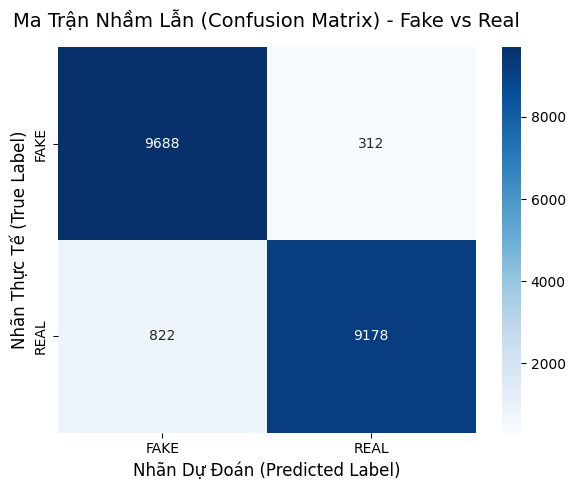

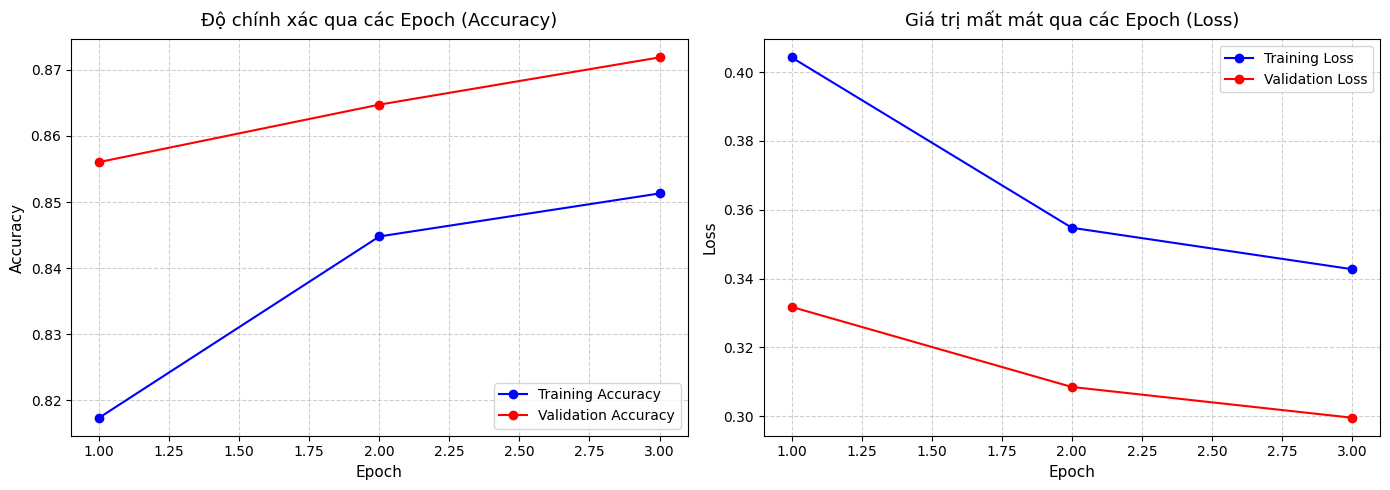

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Tính toán ma trận nhầm lẫn từ nhãn thực tế và nhãn dự đoán
cm = confusion_matrix(true_classes, predicted_classes)

# 2. Cấu hình kích thước và giao diện biểu đồ
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,          # Hiển thị số lượng ảnh trên từng ô
    fmt='d',             # Định dạng số nguyên (không hiển thị số thập phân)
    cmap='Blues',        # Tông màu xanh dương trực quan
    xticklabels=['FAKE', 'REAL'], # Nhãn trục hoành (Dự đoán)
    yticklabels=['FAKE', 'REAL']  # Nhãn trục tung (Thực tế)
)

# 3. Thêm tiêu đề và nhãn cho các trục
plt.title('Ma Trận Nhầm Lẫn (Confusion Matrix) - Fake vs Real', fontsize=14, pad=15)
plt.ylabel('Nhãn Thực Tế (True Label)', fontsize=12)
plt.xlabel('Nhãn Dự Đoán (Predicted Label)', fontsize=12)

# 4. Hiển thị biểu đồ lên màn hình Colab
plt.tight_layout()
plt.show()


# Lấy dữ liệu lịch sử huấn luyện từ biến history
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

# Thiết lập kích thước khung hình cho cả 2 biểu đồ
plt.figure(figsize=(14, 5))

# ----------------------------------------------------
# 1. BIỂU ĐỒ ĐỘ CHÍNH XÁC (ACCURACY GRAPH)
# ----------------------------------------------------
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'b-o', label='Training Accuracy')
plt.plot(epochs_range, val_acc, 'r-o', label='Validation Accuracy')
plt.title('Độ chính xác qua các Epoch (Accuracy)', fontsize=13, pad=10)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Accuracy', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')

# ----------------------------------------------------
# 2. BIỂU ĐỒ GIÁ TRỊ MẤT MÁT (LOSS GRAPH)
# ----------------------------------------------------
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'b-o', label='Training Loss')
plt.plot(epochs_range, val_loss, 'r-o', label='Validation Loss')
plt.title('Giá trị mất mát qua các Epoch (Loss)', fontsize=13, pad=10)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')

# Hiển thị cặp biểu đồ
plt.tight_layout()
plt.show()

TRÌNH KIỂM TRA ẢNH FAKE VS REAL

--- TRÌNH KIỂM TRA ẢNH FAKE VS REAL ---


Saving F (2).jpg to F (2).jpg


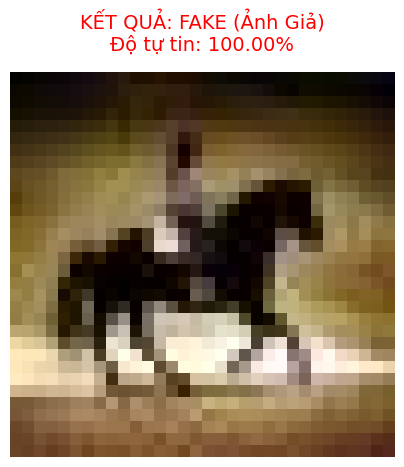

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from tensorflow.keras.preprocessing import image

print("--- TRÌNH KIỂM TRA ẢNH FAKE VS REAL ---")
# 1. Yêu cầu người dùng tải ảnh lên từ máy tính
uploaded = files.upload()

for file_name in uploaded.keys():
    # 2. Đọc và tiền xử lý ảnh để khớp với đầu vào của mô hình
    img_path = file_name
    img = image.load_img(img_path, target_size=(128, 128)) # Kích thước 128x128 như lúc train
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)          # Thêm chiều batch size (1, 128, 128, 3)
    img_array = img_array / 255.0                          # Chuẩn hóa pixel về [0, 1]

    # 3. Đưa ảnh vào mô hình để dự đoán
    prediction = model.predict(img_array, verbose=0)[0][0]

    # 4. Hiển thị kết quả trực quan
    # Đọc ảnh gốc bằng OpenCV để hiển thị đúng màu sắc bằng Matplotlib
    display_img = cv2.imread(img_path)
    display_img = cv2.cvtColor(display_img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(5, 5))
    plt.imshow(display_img)
    plt.axis('off') # Ẩn trục tọa độ

    # Phân loại dựa trên ngưỡng 0.5 (Do nhãn REAL = 1, FAKE = 0)
    if prediction > 0.5:
        confidence = prediction * 100
        result_text = f"KẾT QUẢ: REAL (Ảnh Thật)\nĐộ tự tin: {confidence:.2f}%"
        title_color = 'green'
    else:
        confidence = (1 - prediction) * 100
        result_text = f"KẾT QUẢ: FAKE (Ảnh Giả)\nĐộ tự tin: {confidence:.2f}%"
        title_color = 'red'

    plt.title(result_text, fontsize=14, color=title_color, pad=15)
    plt.show()